# Base 4: exploração, ACF, STL e tratamento

Este notebook transforma apenas a entrada estrutural da Base 4 em um CSV `cleaned`, sem alterar os arquivos congelados. A ACF e a STL usam o maior segmento regular e completo do alvo, sem preencher ausências somente para gerar gráfico.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "configs").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from discovery_series_temporais.cleaning import build_cleaned_dataset, plot_cleaned_diagnostics

BASE_ID = 4
cleaned, summary = build_cleaned_dataset(BASE_ID, ROOT / "data" / "processed")
display(pd.DataFrame([{
    "base": summary.base_id,
    "target_original": summary.target_name,
    "rows": summary.rows,
    "columns": summary.columns,
    "missing_target": summary.missing_target,
    "cleaned_output": str(summary.output_path),
    "actions": "; ".join(summary.actions),
}]))
display(cleaned.head())
display(cleaned.isna().sum().rename("missing_values").to_frame())


,base,target_original,rows,columns,missing_target,cleaned_output,actions
0,4,T (degC),70129,16,88,C:\Users\mayumishimizu-ieg\.codex\.chatgpt-pro...,aggregated valid ten-minute numeric readings b...


,timestamp,target,p (mbar),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wind_direction_sin,wind_direction_cos
0,2009-01-01 00:00:00,-8.304000,996.528000,265.118000,-9.120000,93.780000,3.260000,3.058000,0.202000,1.910000,3.068000,1309.196000,0.520000,1.002000,0.086357,-0.874474
1,2009-01-01 01:00:00,-8.065000,996.525000,265.361667,-8.861667,93.933333,3.323333,3.121667,0.201667,1.951667,3.133333,1307.981667,0.316667,0.711667,0.100133,-0.901708
2,2009-01-01 02:00:00,-8.763333,996.745000,264.645000,-9.610000,93.533333,3.145000,2.940000,0.201667,1.836667,2.950000,1311.816667,0.248333,0.606667,-0.185926,-0.759236
3,2009-01-01 03:00:00,-8.896667,996.986667,264.491667,-9.786667,93.200000,3.111667,2.898333,0.210000,1.811667,2.906667,1312.813333,0.176667,0.606667,0.354961,-0.729819
4,2009-01-01 04:00:00,-9.348333,997.158333,264.026667,-10.345000,92.383333,3.001667,2.775000,0.231667,1.733333,2.780000,1315.355000,0.290000,0.670000,0.294573,-0.465289


,missing_values
timestamp,0
target,88
p (mbar),88
Tpot (K),88
Tdew (degC),88
rh (%),88
VPmax (mbar),88
VPact (mbar),88
VPdef (mbar),88
sh (g/kg),88


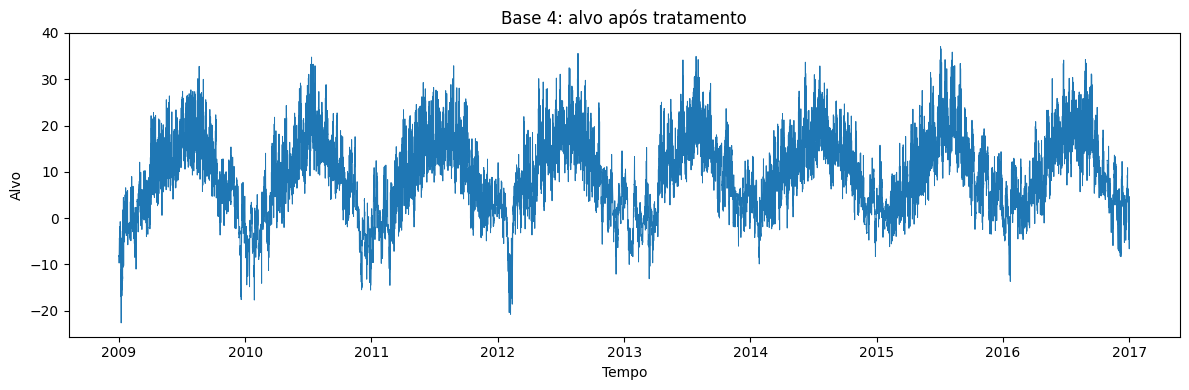

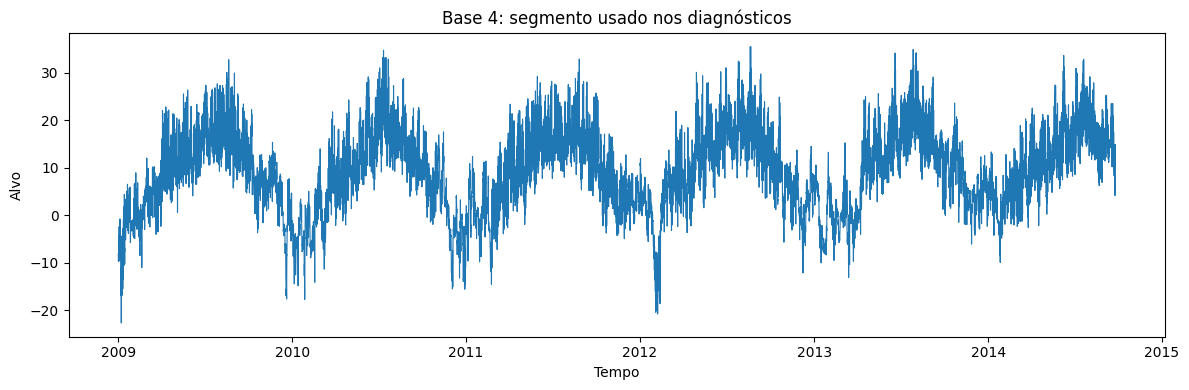

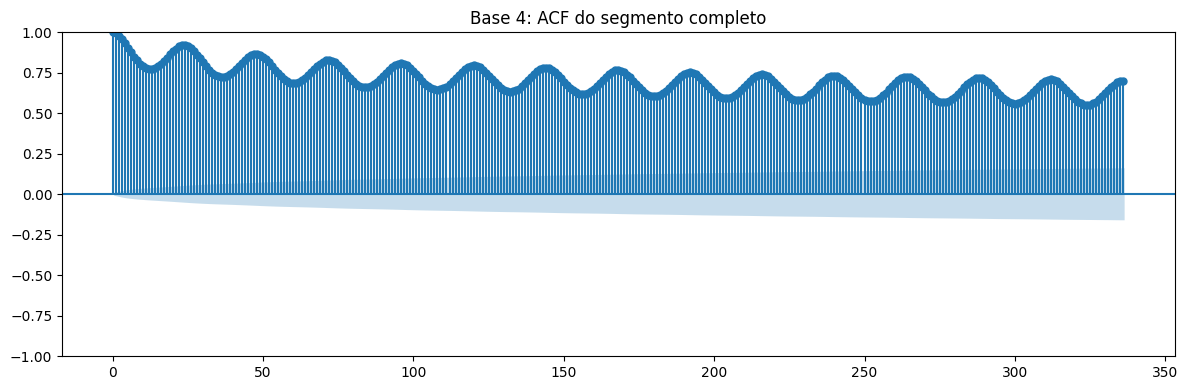

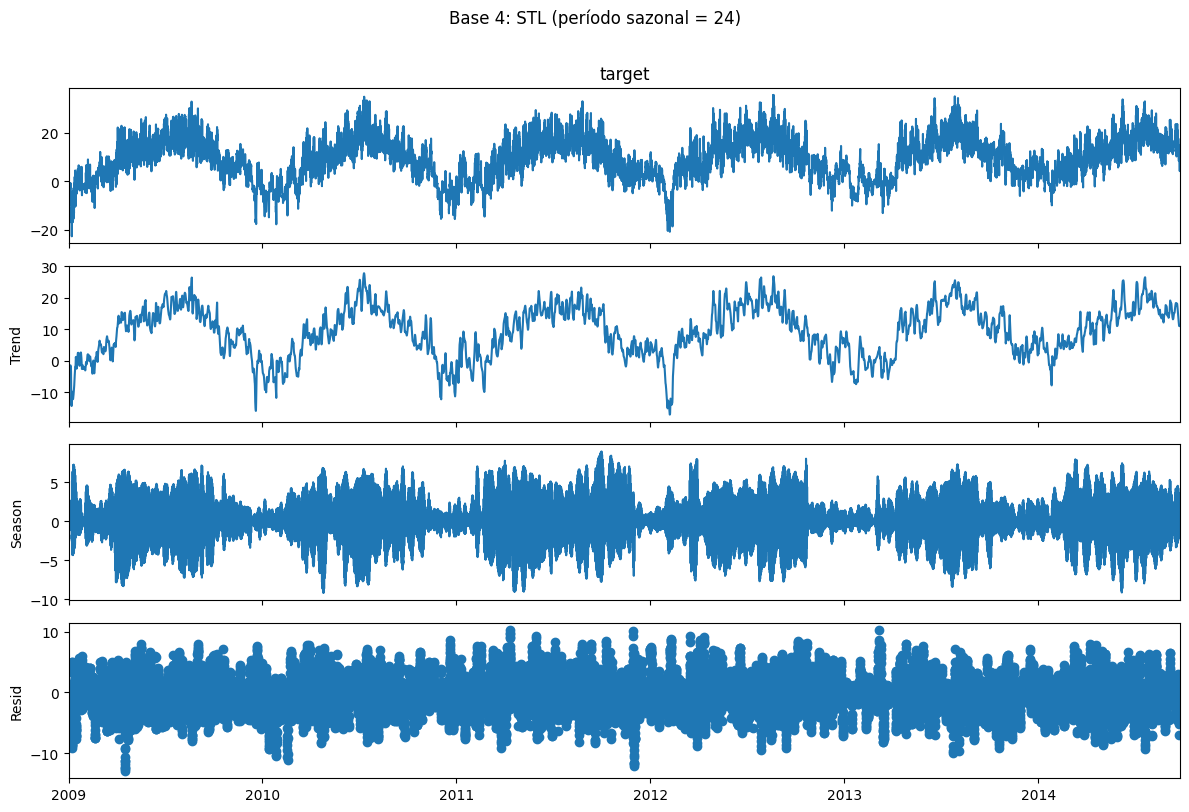

,segment_start,segment_end,segment_points,stl_seasonal_period,acf_lags
0,2009-01-01,2014-09-24 17:00:00,50226,24,336


In [2]:
figure, axis = plt.subplots(figsize=(12, 4))
axis.plot(cleaned["timestamp"], cleaned["target"], linewidth=0.7)
axis.set(title=f"Base {BASE_ID}: alvo após tratamento", xlabel="Tempo", ylabel="Alvo")
figure.tight_layout()
plt.show()

diagnostic = plot_cleaned_diagnostics(
    cleaned,
    BASE_ID,
    ROOT / "reports" / "generated" / "exploration" / f"base{BASE_ID}",
)
display(pd.DataFrame([{
    "segment_start": diagnostic.data["timestamp"].min(),
    "segment_end": diagnostic.data["timestamp"].max(),
    "segment_points": len(diagnostic.data),
    "stl_seasonal_period": diagnostic.seasonal_period,
    "acf_lags": diagnostic.acf_lags,
}]))
